# Reading d-separation in directed acyclic graphs

A directed graph records variables and ordered relations, and it is acyclic when no directed walk returns to its starting node:

$$
G = (V,E),\qquad E\subseteq V\times V,\qquad \nexists\,(v_0,\ldots,v_k):v_0=v_k\text{ and }v_{i-1}\to v_i\ \forall i.
$$

Here, $G$ is the graph, $V$ is its node set, $E$ is its directed-edge set, $v_i$ is the node visited at step $i$, $k$ is the number of steps in a proposed cycle, and $\nexists$ states that no directed cycle exists.

Row,Motif,Pattern,Middle node,Path state without conditioning
,String,String,String,String
1,Chain,X to M to Y,M,Active
2,Common cause,X from C to Y,C,Active
3,Collider,X to K from Y,K,Blocked


Row,Motif,From,To
,String,String,String
1,Chain,X,M
2,Chain,M,Y
3,Common cause,C,X
4,Common cause,C,Y
5,Collider,X,K
6,Collider,Y,K


Row,Motif,Nodes,Directed edges,Acyclic,Roots,Sinks
,String,Int64,Int64,Bool,Int64,Int64
1,Chain,3,2,true,1,1
2,Common cause,3,2,true,1,2
3,Collider,3,2,true,2,1


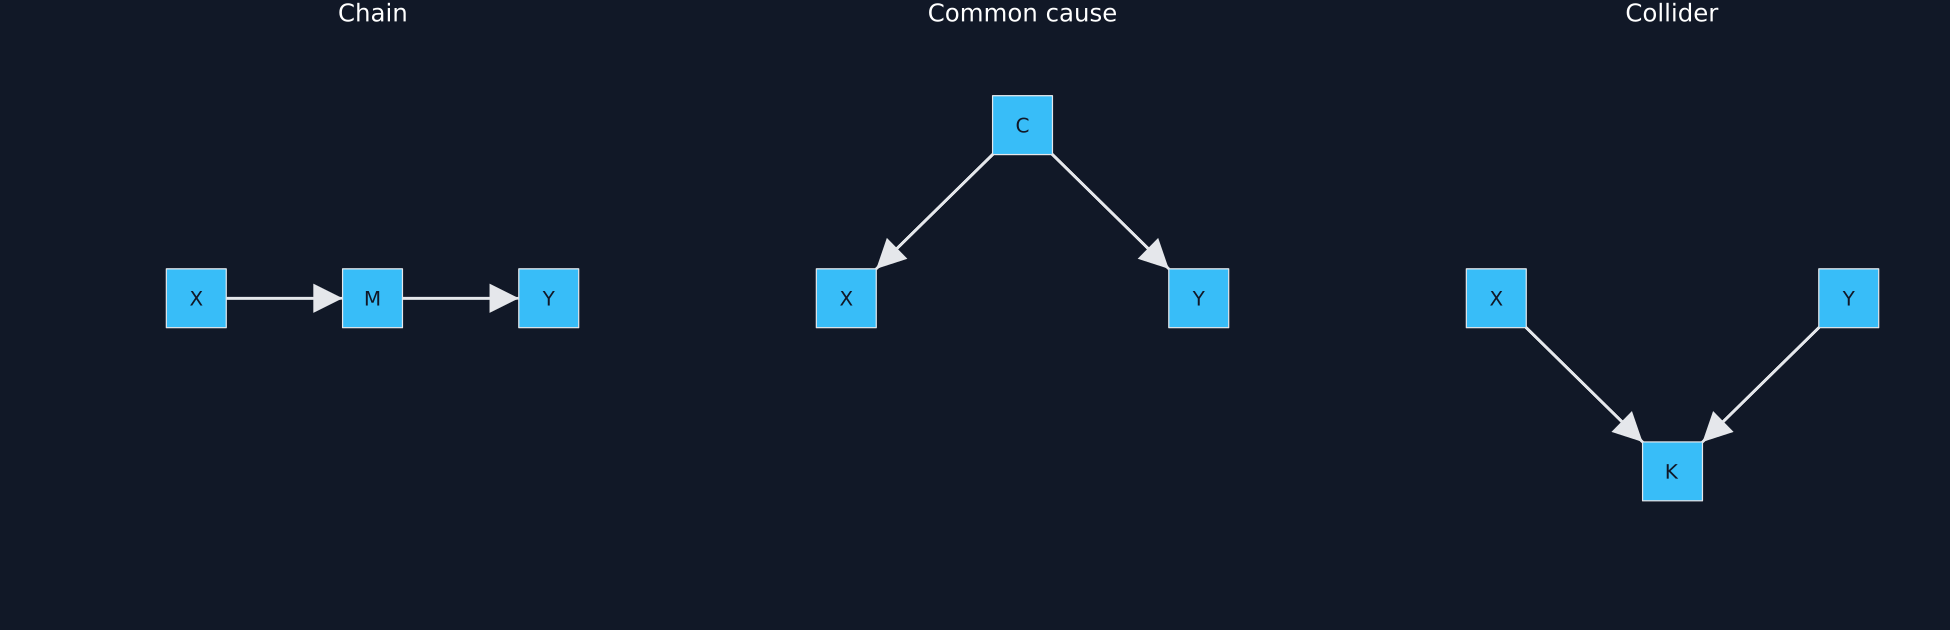

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("01_causal_roles");
using CSV, TOML
include(joinpath("..","support","CausalNotebookTools.jl"))
using .CausalNotebookTools
include(joinpath("..","support","BookCausalStudy.jl"))
using .BookCausalStudy
import .BookCausalStudy: frame
using RiskLabAI.CausalFactorAnalysis: d_separation
default(left_margin=10Plots.mm,bottom_margin=10Plots.mm)
input_directory = joinpath("..","data","chapter01_random_inputs")
table(values,name,caption) = save_table(values,paths,name;caption,label="tab:chapter23-"*replace(name,"_"=>"-"))
matrix_data(values) = DataFrame(values,:auto)
function assert_artifacts(figures,tables)
    @assert all(name->isfile(joinpath(paths.figures,name*".pdf")),figures)
    @assert all(name->isfile(joinpath(paths.tables,name*".tex")),tables)
end
motifs = ["Chain"=>DirectedGraph([("X","M"),("M","Y")]),"Common cause"=>DirectedGraph([("C","X"),("C","Y")]),"Collider"=>DirectedGraph([("X","K"),("Y","K")])]
motif_definitions = frame(["Motif","Pattern","Middle node","Path state without conditioning"],[["Chain","X to M to Y","M","Active"],["Common cause","X from C to Y","C","Active"],["Collider","X to K from Y","K","Blocked"]])
motif_edges = frame(["Motif","From","To"],[(name,left,right) for (name,graph) in motifs for (left,right) in ordered_edges(graph)])
graph_structure_summary = frame(["Motif","Nodes","Directed edges","Acyclic","Roots","Sinks"],[(name,length(graph.nodes),length(graph.edges),acyclic(graph),count(node->all(edge->edge[2]!=node,graph.edges),graph.nodes),count(node->all(edge->edge[1]!=node,graph.edges),graph.nodes)) for (name,graph) in motifs])
table(motif_definitions,"motif_definitions","Three elementary path motifs.")
table(motif_edges,"motif_edges","Directed edges in the three elementary motifs.")
table(graph_structure_summary,"graph_structure_summary","Structural checks for the elementary motifs.")
motif_positions = Dict("X"=>(0.,0.),"M"=>(1.,0.),"Y"=>(2.,0.),"C"=>(1.,1.),"K"=>(1.,-1.))
save_figure(plot([plot(graph_panel(graph,motif_positions,name);ylims=(-1.4,1.4)) for (name,graph) in motifs]...;layout=(1,3),size=(1300,420)),paths,"elementary_causal_motifs")


## Determining whether a graph path is blocked

A path is active given a conditioning set when every noncollider on the path is outside that set and every collider has itself or a descendant in the set:

$$
A(\pi\mid S)=\prod_{m\in N(\pi)}\mathbf 1\{m\notin S\}\prod_{c\in C(\pi)}\mathbf 1\{c\in\operatorname{An}(S)\},
$$

Here, $\pi$ is a path, $S$ is the conditioning set, $N(\pi)$ is the set of internal noncolliders, $C(\pi)$ is the set of internal colliders, $\operatorname{An}(S)$ contains the nodes in $S$ and their ancestors, $\mathbf 1\{\cdot\}$ is an indicator, and $A(\pi\mid S)$ equals one exactly when the path is active.

Row,Motif,Path,Conditioning set,Collider nodes,Path state
,String,String,String,String,String
1,Chain,X - M - Y,None,None,Active
2,Chain,X - M - Y,M,None,Blocked
3,Common cause,X - C - Y,None,None,Active
4,Common cause,X - C - Y,C,None,Blocked
5,Collider,X - K - Y,None,K,Blocked
6,Collider,X - K - Y,K,K,Active


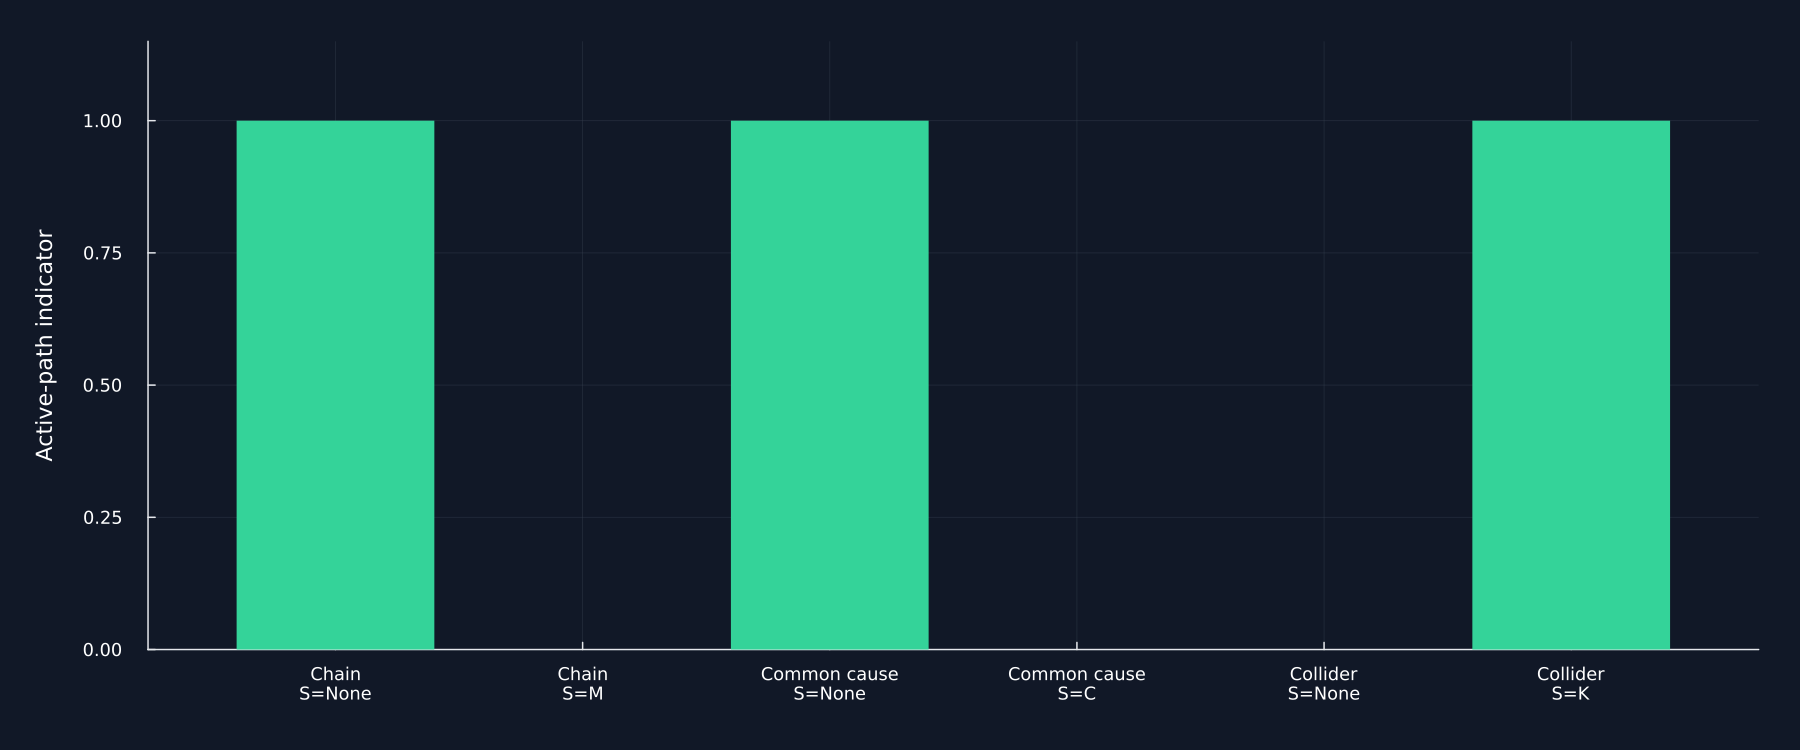

In [2]:
middle_nodes = ["M","C","K"]
path_rows = Tuple[]
for ((name,graph),middle) in zip(motifs,middle_nodes),conditioned in [String[],[middle]]
    records = path_records(graph,"X","Y",conditioned)
    append!(path_rows,[(name,row[1],row[2],row[3],row[4]) for row in eachrow(records)])
end
motif_path_status = frame(["Motif","Path","Conditioning set","Collider nodes","Active"],path_rows)
motif_path_status[!,"Path state"] = ifelse.(motif_path_status.Active,"Active","Blocked")
table(select(motif_path_status,Not(:Active)),"motif_path_status","Path states before and after conditioning on the middle node.")
path_labels = [row.Motif*"\nS="*row["Conditioning set"] for row in eachrow(motif_path_status)]
figure = bar(1:6,Int.(motif_path_status.Active);color=ifelse.(motif_path_status.Active,palette.green,palette.rose),linealpha=0,xticks=(1:6,path_labels),ylabel="Active-path indicator",ylims=(0,1.15),legend=false,size=(1200,500))
save_figure(figure,paths,"motif_path_states")


## Graph Factorization

A probability distribution compatible with a directed acyclic graph factors into one conditional term for each node given its parents:

$$
p(x_1,\ldots,x_p)=\prod_{j=1}^{p}p\!\left(x_j\mid x_{\operatorname{pa}(j)}\right).
$$

Here, $p$ is the number of variables, $x_j$ is the realized value of node $j$, $\operatorname{pa}(j)$ is the parent set of node $j$, $x_{\operatorname{pa}(j)}$ contains the realized parent values, and $p(\cdot)$ denotes a joint or conditional density.

In [3]:
motif_factorizations = frame(["Motif","Factorization","Implied separation"],[["Chain","p(X) p(M | X) p(Y | M)","X independent of Y given M"],["Common cause","p(C) p(X | C) p(Y | C)","X independent of Y given C"],["Collider","p(X) p(Y) p(K | X,Y)","X independent of Y before conditioning"]])
table(motif_factorizations,"motif_factorizations","Factorizations and elementary graph separations.")


Row,Motif,Factorization,Implied separation
,String,String,String
1,Chain,p(X) p(M | X) p(Y | M),X independent of Y given M
2,Common cause,p(C) p(X | C) p(Y | C),X independent of Y given C
3,Collider,"p(X) p(Y) p(K | X,Y)",X independent of Y before conditioning


## Comparing marginal association with conditional association

With one conditioning variable, partial correlation removes the two linear associations that pass through that variable:

$$
\rho_{XY\cdot Z}=\frac{\rho_{XY}-\rho_{XZ}\rho_{YZ}}{\sqrt{(1-\rho_{XZ}^{2})(1-\rho_{YZ}^{2})}}.
$$

Here, $X$ and $Y$ are the variables being compared, $Z$ is the conditioning variable, $\rho_{XY}$ is their marginal correlation, $\rho_{XZ}$ and $\rho_{YZ}$ are their correlations with $Z$, and $\rho_{XY\cdot Z}$ is their partial correlation after linear adjustment for $Z$.

Row,Motif,Observations,Marginal correlation,Correlation after conditioning,Absolute change
,String,Int64,Float64,Float64,Float64
1,Chain,20000,0.522134,0.0117246,0.51041
2,Common cause,20000,0.442947,0.0052211,0.437726
3,Collider,20000,0.0107446,-0.434367,0.445111


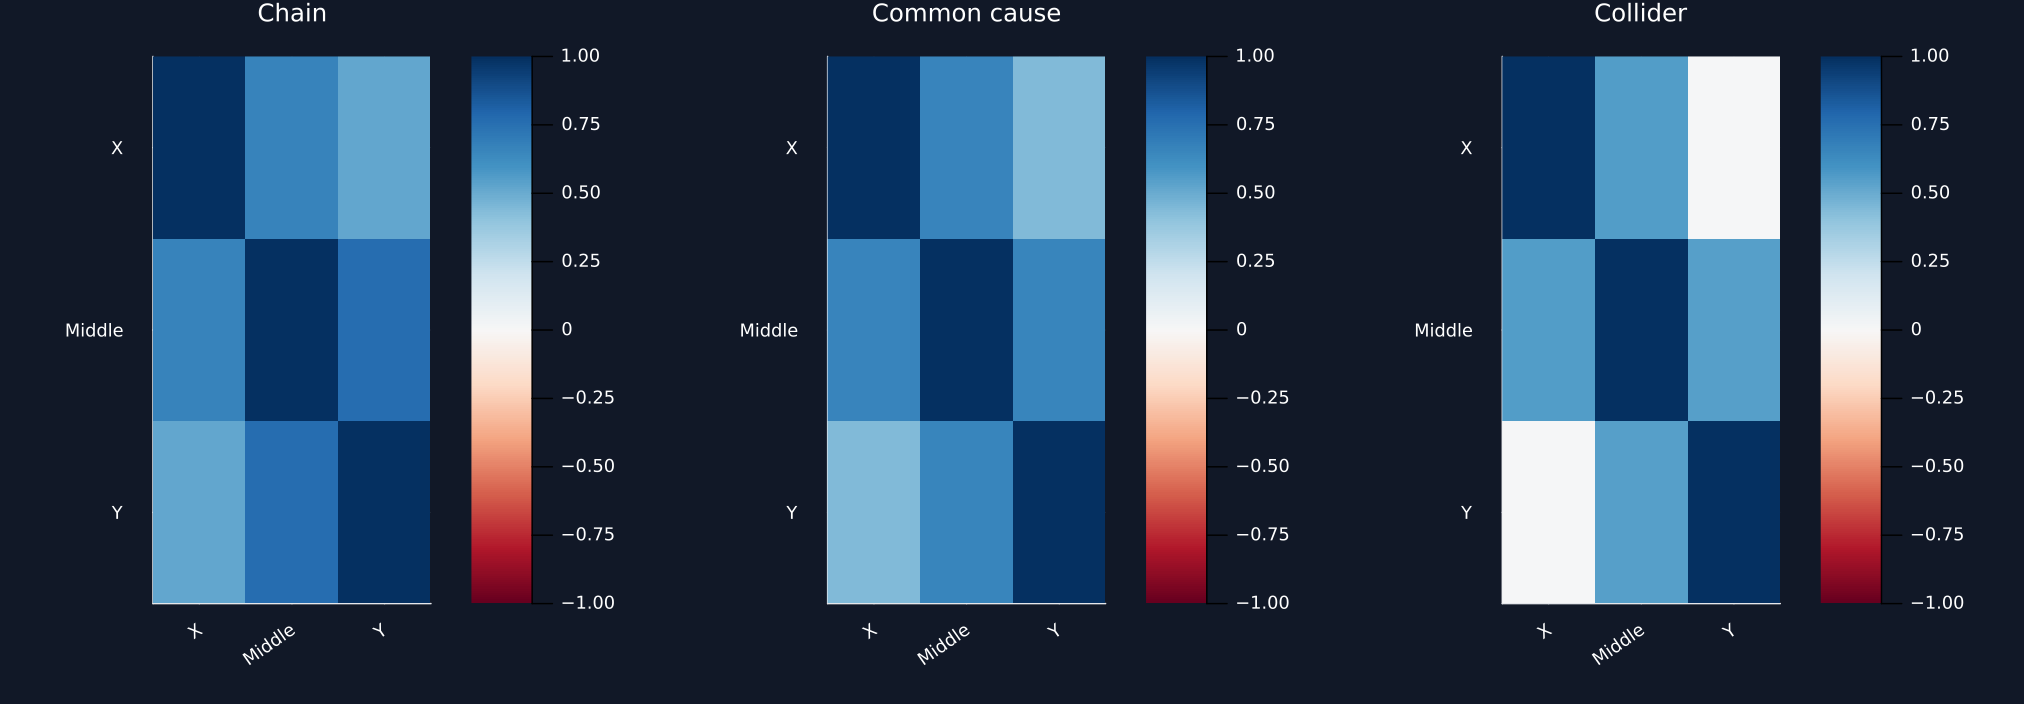

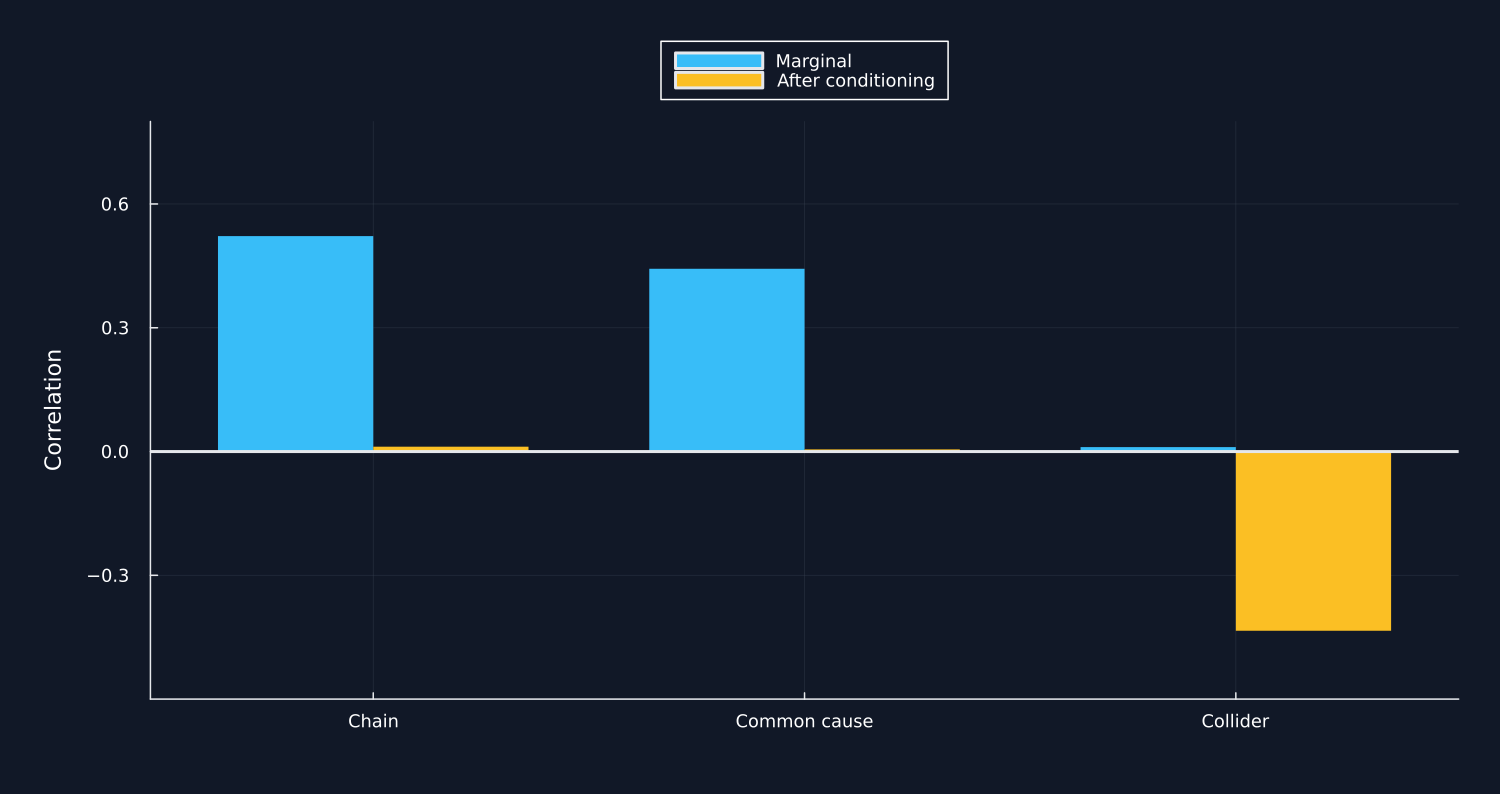

In [4]:
sample_size,coefficient = 20000,.9
innovations = primitive_input(input_directory,2301)
x,m = innovations[:,1],coefficient.*innovations[:,1]+innovations[:,2]
chain = DataFrame(X=x,Middle=m,Y=coefficient.*m+innovations[:,3])
c = innovations[:,4]
fork = DataFrame(X=coefficient.*c+innovations[:,5],Middle=c,Y=coefficient.*c+innovations[:,6])
x,y = innovations[:,7],innovations[:,8]
collider = DataFrame(X=x,Middle=coefficient.*x+coefficient.*y+innovations[:,9],Y=y)
samples = ["Chain"=>chain,"Common cause"=>fork,"Collider"=>collider]
association_rows = Tuple[]
for (index,(name,values)) in enumerate(samples)
    marginal = partial_correlation(values.X,values.Y)
    conditional = partial_correlation(values.X,values.Y,values[:,[:Middle]])
    push!(association_rows,(name,nrow(values),marginal,conditional,abs(conditional-marginal)))
    save_data(values,paths,"motif_sample_"*string(index))
    save_data(matrix_data(cor(Matrix(values))),paths,"motif_correlation_"*string(index))
end
motif_association_summary = frame(["Motif","Observations","Marginal correlation","Correlation after conditioning","Absolute change"],association_rows)
table(motif_association_summary,"motif_association_summary","Marginal and conditional associations in the known-graph examples.")
save_figure(plot([matrix_panel(cor(Matrix(values)),["X","Middle","Y"],name) for (name,values) in samples]...;layout=(1,3),size=(1350,470)),paths,"motif_sample_correlations")
figure = bar((1:3).- .18,motif_association_summary[!,"Marginal correlation"];bar_width=.36,color=palette.cyan,linealpha=0,label="Marginal",xticks=(1:3,first.(samples)),ylabel="Correlation",ylims=(-.6,.8),legend=:outertop,size=(1000,530))
bar!(figure,(1:3).+ .18,motif_association_summary[!,"Correlation after conditioning"];bar_width=.36,color=palette.amber,linealpha=0,label="After conditioning")
hline!(figure,[0];color=palette.text,label="")
save_figure(figure,paths,"motif_conditioning_effects")


## Reading conditional independence through d-separation

Graph separation implies conditional independence for every distribution compatible with the graph:

$$
X\perp_G Y\mid S\quad\Longrightarrow\quad X\perp Y\mid S.
$$

Here, $X$ and $Y$ are disjoint node sets, $S$ is the conditioning set, $\perp_G$ denotes d-separation in graph $G$, $\perp$ denotes conditional independence in the probability distribution, and the implication requires compatibility between the distribution and the graph.

Row,Motif,Conditioning set,Paths,Active paths,d-separated
,String,String,Int64,Int64,Bool
1,Chain,None,1,1,false
2,Chain,M,1,0,true
3,Common cause,None,1,1,false
4,Common cause,C,1,0,true
5,Collider,None,1,0,true
6,Collider,K,1,1,false


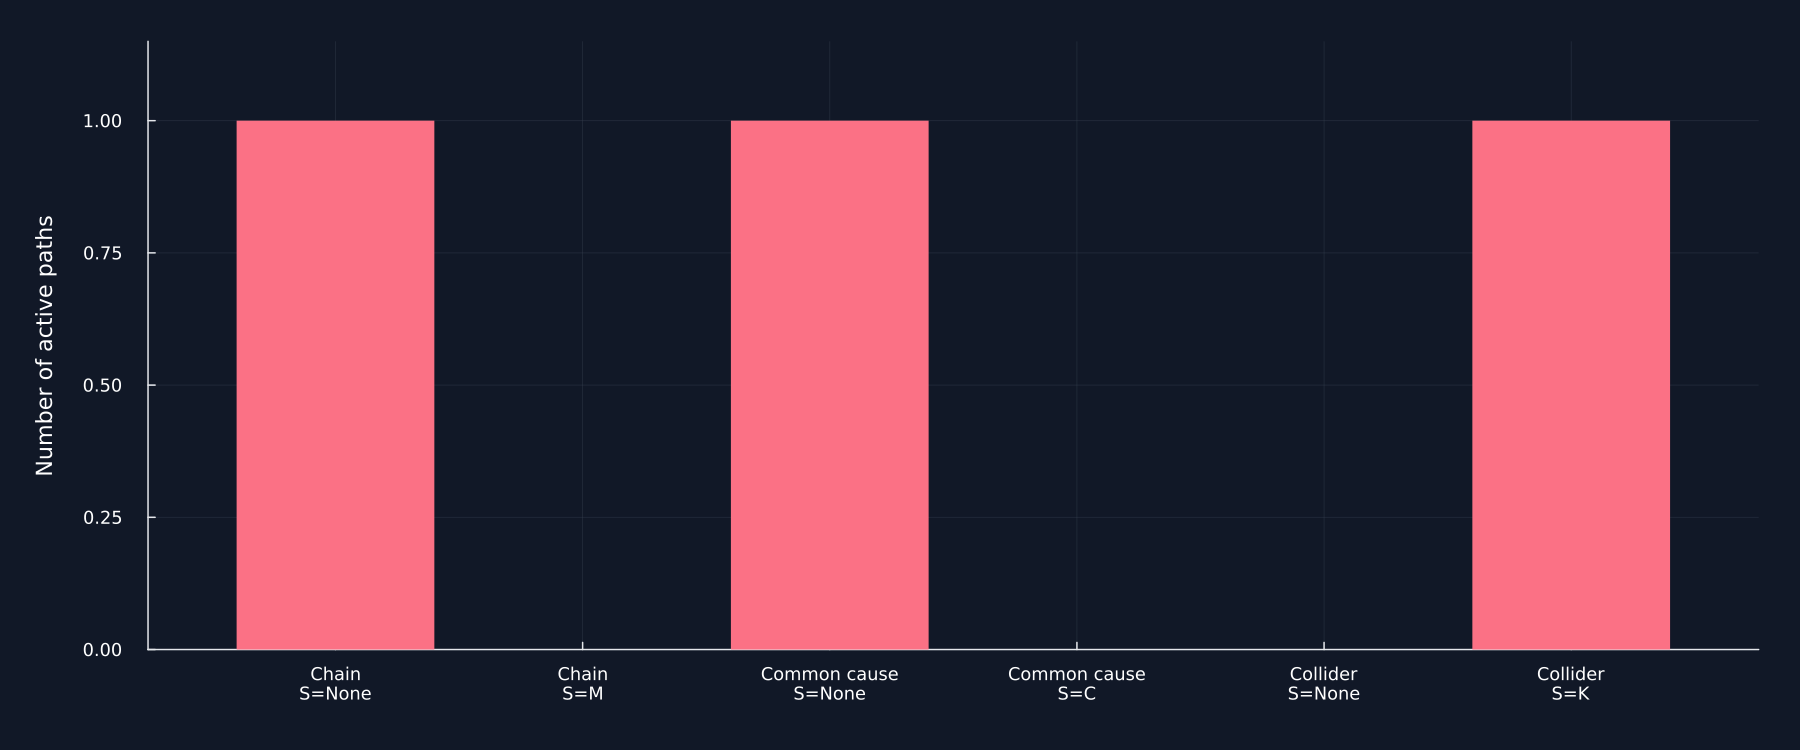

In [5]:
dseparation_rows = Tuple[]
for ((name,graph),middle) in zip(motifs,middle_nodes),conditioned in [String[],[middle]]
    records = path_records(graph,"X","Y",conditioned)
    active_count = count(records.Active)
    public_evidence = d_separation(CausalDAG(graph.nodes,graph.edges,graph.nodes),["X"],["Y"],conditioned)
    @assert public_evidence.separated==(active_count==0)
    push!(dseparation_rows,(name,isempty(conditioned) ? "None" : middle,nrow(records),active_count,active_count==0))
end
dseparation_grid = frame(["Motif","Conditioning set","Paths","Active paths","d-separated"],dseparation_rows)
table(dseparation_grid,"dseparation_grid","D-separation decisions for the elementary motifs.")
figure = bar(1:6,dseparation_grid[!,"Active paths"];color=ifelse.(dseparation_grid[!,"Active paths"].>0,palette.rose,palette.green),linealpha=0,xticks=(1:6,path_labels),ylabel="Number of active paths",ylims=(0,1.15),legend=false,size=(1200,500))
save_figure(figure,paths,"dseparation_active_path_counts")


## Observational Equivalence

Two directed acyclic graphs are observationally equivalent when they encode the same conditional-independence model:

$$
\mathcal M(G_1)=\mathcal M(G_2)\quad\Longleftrightarrow\quad \operatorname{skel}(G_1)=\operatorname{skel}(G_2)\ \text{ and }\ \operatorname{col}(G_1)=\operatorname{col}(G_2).
$$

Here, $\mathcal M(G)$ is the set of graph-compatible distributions, $\operatorname{skel}(G)$ is the undirected skeleton, $\operatorname{col}(G)$ is the set of unshielded collider structures, and $G_1$ and $G_2$ are two candidate graphs on the same nodes.

Row,Graph,Edges,Unshielded colliders,Maximum covariance error,Smallest residual variance
,String,Int64,Int64,Float64,Float64
1,Forward chain,2,0,4.44089e-16,1.0
2,Reverse chain,2,0,0.0,0.609756
3,Common cause,2,0,0.0,0.609756


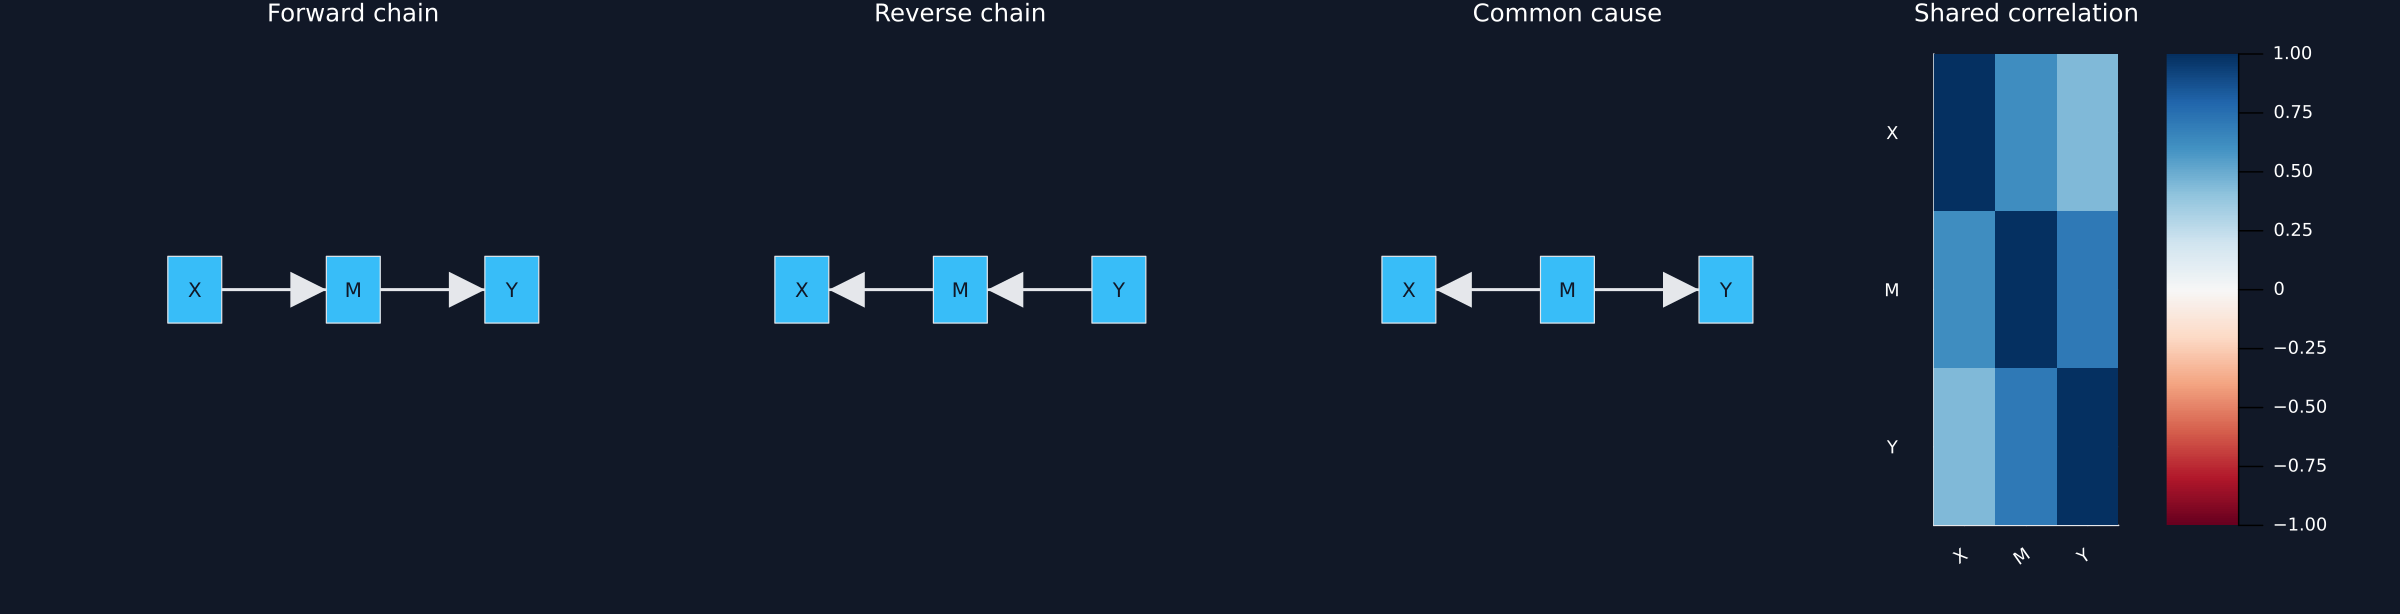

Row,Quantity,Value
,String,Int64
1,Elementary graphs,3
2,Generated observations per graph,20000
3,Conditioning decisions,6
4,Equivalent graph orientations,3
5,Figures,6
6,Generated tables,9


In [6]:
equivalent_graphs = ["Forward chain"=>DirectedGraph([("X","M"),("M","Y")]),"Reverse chain"=>DirectedGraph([("Y","M"),("M","X")]),"Common cause"=>DirectedGraph([("M","X"),("M","Y")])]
a,b = .8,.8
theoretical_covariance = [1. a a*b; a a^2+1 b*(a^2+1); a*b b*(a^2+1) b^2*(a^2+1)+1]
equivalent_rows = Tuple[]
for (index,(name,graph)) in enumerate(equivalent_graphs)
    coefficients,residual,implied = fit_sem_covariance(theoretical_covariance,graph,["X","M","Y"])
    push!(equivalent_rows,(name,length(graph.edges),0,maximum(abs,implied-theoretical_covariance),minimum(residual)))
    save_data(matrix_data(coefficients),paths,"equivalent_coefficients_"*string(index))
    save_data(DataFrame(variance=residual),paths,"equivalent_variances_"*string(index))
end
markov_equivalence_summary = frame(["Graph","Edges","Unshielded colliders","Maximum covariance error","Smallest residual variance"],equivalent_rows)
table(markov_equivalence_summary,"markov_equivalence_summary","Three observationally equivalent factorizations of one covariance matrix.")
correlation = theoretical_covariance./sqrt.(diag(theoretical_covariance)*diag(theoretical_covariance)')
panels = [plot(graph_panel(graph,motif_positions,name);ylims=(-1.2,1.2)) for (name,graph) in equivalent_graphs]
push!(panels,matrix_panel(correlation,["X","M","Y"],"Shared correlation"))
save_figure(plot(panels...;layout=(1,4),size=(1600,410)),paths,"markov_equivalent_factorizations")
section_summary = DataFrame("Quantity"=>["Elementary graphs","Generated observations per graph","Conditioning decisions","Equivalent graph orientations","Figures","Generated tables"],"Value"=>[length(motifs),sample_size,nrow(dseparation_grid),length(equivalent_graphs),6,9])
table(section_summary,"dag_section_summary","Section 23.1 numerical summary.")


## Tests

In [7]:
@assert all(acyclic(last(pair)) for pair in motifs)
@assert all(graph_structure_summary.Nodes.==3)
@assert all(graph_structure_summary[!,"Directed edges"].==2)
@assert nrow(motif_path_status)==6
@assert motif_path_status.Active==[true,false,true,false,false,true]
@assert nrow(motif_factorizations)==3
@assert nrow(motif_association_summary)==3
@assert abs(motif_association_summary[1,"Correlation after conditioning"])<.03
@assert abs(motif_association_summary[2,"Correlation after conditioning"])<.03
@assert motif_association_summary[3,"Correlation after conditioning"]<-.35
@assert nrow(dseparation_grid)==6
@assert dseparation_grid[!,"d-separated"]==[false,true,false,true,true,false]
@assert nrow(markov_equivalence_summary)==3
@assert maximum(markov_equivalence_summary[!,"Maximum covariance error"])<1e-12
@assert minimum(markov_equivalence_summary[!,"Smallest residual variance"])>0
@assert nrow(section_summary)==6
assert_artifacts(["elementary_causal_motifs","motif_path_states","motif_sample_correlations","motif_conditioning_effects","dseparation_active_path_counts","markov_equivalent_factorizations"],["motif_definitions","motif_edges","graph_structure_summary","motif_path_status","motif_factorizations","motif_association_summary","dseparation_grid","markov_equivalence_summary","dag_section_summary"])
nothing
